> **Notebook repair note (Lab 3):** Fixed the indentation/syntax in the Shapiro–Wilk and Wilcoxon cells, removed a stray incomplete expression, and replaced `eval` in the duration cell. The previously stored charts/results were not recomputed here. The Lab 3 pipeline and its tests are provided separately in the project archive.

#1.	Brief context



Depression is a common mental disorder characterized by persistent changes in mood, often manifested through a loss of interest or pleasure in daily activities and prolonged feelings of sadness or emptiness. It is also associated with an increased risk of self-harm and suicide, making it a significant public health concern. Despite its prevalence, depression frequently remains undetected or untreated due to factors such as social stigma, limited awareness, insufficient mental healthcare resources, and a shortage of trained professionals (World Health Organization, 2026).

To address these challenges, recent research has explored the development of artificial intelligence (AI) models as complementary tools in the assessment and screening of depressive symptoms. These models can analyze measurable behavioral characteristics, potentially providing additional information to support clinical evaluations. Furthermore, automated analysis could reduce the time required for certain assessment tasks and improve the scalability of mental healthcare services. Since some approaches rely on voice recordings and visual information collected during clinical interviews, they may be incorporated into existing assessment procedures without requiring substantially more complex acquisition methods (Mao et al., 2023).

These AI-based approaches commonly analyze signals such as voice recordings and video data, including facial expressions and body movements, to identify patterns potentially associated with depressive symptoms. For this assignment, the Ryerson Audio-Visual Database of Emotional Speech and Song (RAVDESS) was selected to explore the processing and analysis of emotional speech signals. The database contains audio and video recordings from 24 professional actors performing two predefined statements through speech and song while expressing different emotions, including happiness, sadness, anger, fear, and neutrality. The recordings were produced under controlled conditions and include variations in emotional intensity (Livingstone & Russo, 2018).

Emotion recognition is relevant to the study of depression because emotional expression and affective behavior may provide useful information during the assessment of depressive symptoms (Mao et al., 2023). Although recognizing emotions does not directly indicate the presence of depression, analyzing emotional speech can contribute to understanding acoustic characteristics potentially relevant to automated screening systems. Therefore, RAVDESS provides a suitable resource for exploring audio processing and feature extraction techniques. Additionally, the database is freely accessible and can be downloaded without registration or special authorization, facilitating its use in academic research (Livingstone & Russo, 2018).

Livingstone, S. R., & Russo, F. A. (2018). The Ryerson Audio-Visual Database of Emotional Speech and Song (RAVDESS): A dynamic, multimodal set of facial and vocal expressions in North American English. PLOS ONE, 13(5), Article e0196391. https://doi.org/10.1371/journal.pone.0196391

Mao, K., Wu, Y., & Chen, J. (2023). A systematic review on automated clinical depression diagnosis. npj Mental Health Research, 2, Article 20. https://doi.org/10.1038/s44184-023-00040-z

World Health Organization. (2026, September 11). Depressive disorder (depression). https://www.who.int/news-room/fact-sheets/detail/depression



#2.	Advanced data handling with Pandas

In [2]:
import os
import librosa
import zipfile
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import shapiro
from scipy.signal.windows import hann
from IPython.display import Audio, display
from IPython.core.interactiveshell import dis

In [3]:
!wget "https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip?download=1" -O /content/ravdess.zip #file downloaded in a temporal drive directory

--2026-11-07 08:08:19--  https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.42.113, 188.185.47.192, 188.185.40.132, ...
Connecting to zenodo.org (zenodo.org)|188.185.42.113|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 208468073 (199M) [application/octet-stream]
Saving to: ‘/content/ravdess.zip’

/content/ravdess.zi 100%[===================>] 198.81M   894KB/s    in 2m 36s  

2026-11-07 08:10:55 (1.28 MB/s) - ‘/content/ravdess.zip’ saved [208468073/208468073]



In [4]:
from librosa.core import audio
zip_path = '/content/ravdess.zip'


with zipfile.ZipFile(zip_path, "r") as z:

    wav_files = sorted(f for f in z.namelist() if f.endswith(".wav"))#orders the files and makes sure is only tking the .wav ones
    audio_path0 = z.extract(wav_files[0], '/content/audio')#each actor has 60 recordings, and since the recordings are in orther, multiples of 60 are the same task of a different actor
    audio_path1 = z.extract(wav_files[60], '/content/audio')
    audio_path2 = z.extract(wav_files[120], '/content/audio')
    audio_path3 = z.extract(wav_files[180], '/content/audio')

print('Extracted:', audio_path0)

Extracted: /content/audio/Actor_01/03-01-01-01-01-01-01.wav


In [5]:
audio0, fs = librosa.load(audio_path0, sr=None)#manual scouting of the info
audio1, _ = librosa.load(audio_path1, sr=None)
audio2, _ = librosa.load(audio_path2, sr=None)
audio3, _ = librosa.load(audio_path3, sr=None)

display(Audio(audio0, rate=fs))
display(Audio(audio1, rate=fs))
display(Audio(audio2, rate=fs))
display(Audio(audio3, rate=fs))


In [6]:
audio0, _ = librosa.load(audio_path0, sr=None)
audio0

array([0., 0., 0., ..., 0., 0., 0.], shape=(158558,), dtype=float32)

In [7]:
print(fs)  # Check sampling rate and recording durations
print(len(audio0))
for i, audio in enumerate([audio0, audio1, audio2, audio3]):
    print(f"For audio {i}, duration: {len(audio) / fs:.3f} seconds")


48000
158558
for 0 audio, the lenght s: 3.3032916666666665 segundos
for 1 audio, the lenght s: 3.6369583333333333 segundos
for 2 audio, the lenght s: 3.4367708333333336 segundos
for 3 audio, the lenght s: 3.3032916666666665 segundos


In [8]:
df = pd.DataFrame({
    'Actor': [0, 1, 2, 3],
    'Audio': [audio0, audio1, audio2, audio3]})#this dataframe contains the list of the recording, not the recording itself

df

,Actor,Audio
0,0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
1,1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
2,2,"[-3.0517578e-05, 0.0, -3.0517578e-05, 0.0, 0.0..."
3,3,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."


In [9]:
def extract_n_audio(zip_path, n , feature = 0):#data extraction with OOP
  audios = []
  with zipfile.ZipFile(zip_path, "r") as z:
    wav_files = [f for f in z.namelist() if f.endswith(".wav")]

    for i in range(n):
      audio_path = z.extract(wav_files[feature + (60*i)], '/content/audio')
#      print('extracted:', eval(f'audio_path{i}'))
      audio, _ = librosa.load(audio_path, sr=None)
      audios.append(audio)

  return audios#list that contains the audios as list, meant to be preserved as unprocesed as possible since this file can be used for general signal analysis (rms, amp,...)

In [10]:
def trunc_audios(audios):#truncation will remove data from the end of the list so it can be worked with pandas, this will affect some features such as the rms, silent related measures, inter alia.
    minL = min(len(audio) for audio in audios)
    audio_matrix = np.stack([audio[:minL] for audio in audios])
    return audio_matrix
  #i know there is no pandas data handling and that i could've used a df_audio.dropna(axis=1) but theres is not point to it, in fact it's less efficient, the pd data handling is shown later

In [11]:
matrix = extract_n_audio(zip_path, 4)#aplication of the functions
print(matrix)

[array([0., 0., 0., ..., 0., 0., 0.], shape=(158558,), dtype=float32), array([0., 0., 0., ..., 0., 0., 0.], shape=(174574,), dtype=float32), array([-3.0517578e-05,  0.0000000e+00, -3.0517578e-05, ...,
        0.0000000e+00,  0.0000000e+00,  0.0000000e+00],
      shape=(164965,), dtype=float32), array([0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 3.0517578e-05,
       0.0000000e+00, 0.0000000e+00], shape=(158558,), dtype=float32)]


In [13]:
trunc_matrix = trunc_audios(matrix)
trunc_matrix

array([[ 0.0000000e+00,  0.0000000e+00,  0.0000000e+00, ...,
         0.0000000e+00,  0.0000000e+00,  0.0000000e+00],
       [ 0.0000000e+00,  0.0000000e+00,  0.0000000e+00, ...,
         0.0000000e+00,  0.0000000e+00,  0.0000000e+00],
       [-3.0517578e-05,  0.0000000e+00, -3.0517578e-05, ...,
         0.0000000e+00,  0.0000000e+00,  3.0517578e-05],
       [ 0.0000000e+00,  0.0000000e+00,  0.0000000e+00, ...,
         3.0517578e-05,  0.0000000e+00,  0.0000000e+00]],
      shape=(4, 158558), dtype=float32)

#3.	Feature extraction using OOP

The features extracted are going to be:

-RMS: it measures signal amplitude related to speech intensity, it is NOT a direct indicator of speech energy but it can reflect the canges of these, since people with depression tend too monotone, it is expected tave few variations.

-peak: maximum absolute value of hthe signal, is weak to noise but can get some data tht the RMS is not capablle of.

-ZCR: measures how frequently the waveform changes from positive to negative or vice versa. It describes aspects of the signal’s oscillatory structure: noisy or unvoiced speech sounds often have higher zero-crossing rates than periodic voiced sounds.

-Espectra centroid: represents the center of the signal’s frequency distribution, calculated by weighting frequencies according to their spectral magnitudes. A higher centroid indicates that more of the spectral magnitude is concentrated at higher frequencies, often associated with a brighter sound. A lower centroid indicates a greater concentration at lower frequencies.

-F0: estimates the repetition frequency of vocal-fold vibration during voiced speech and is closely related to perceived pitch. Its typical value describes the pitch level of a recording, while its variation reflects changes in intonation. Pitch and intoantion are known to change with depression

for each feature the mean, median, standart deviation, min, max and range are going to be calculated, these statisticall measurements can capture both the typical characteristics of the voice and their variability.

In [14]:
def window_feature_extraction(audio_matrix, fs):#these function will only extract the information from the windowing process

  window_size = int(0.025 * fs)
  hop_size = int(0.010 * fs)

  frames = librosa.util.frame(
      audio_matrix,
      frame_length= window_size,
      hop_length= hop_size,
      axis=-1)

  frames = np.swapaxes(frames, -1, -2)#dimensional change, otherwise the hann_window won't work

  hann_window = hann(window_size, sym=False)
  hann_frames = frames * hann_window

  rms = np.sqrt(np.mean(frames**2, axis=-1))#time

  peak = np.max(np.abs(frames), axis=-1)#time

  zcr = np.mean(np.diff(np.signbit(frames), axis=-1), axis=-1  )#time

  spectrum = np.abs(np.fft.rfft(hann_frames, axis=-1))
  frequencies = np.fft.rfftfreq(window_size, d=1/fs)
  centroid = (np.sum(spectrum * frequencies, axis=-1) / (np.sum(spectrum, axis=-1) + 1e-10))#freq


  f0_frame_length = 2 ** int(np.ceil(np.log2(2 * fs / 65)))#freq, F0 requires bigger winndows since it needs at least two cycles of the lower frequency in order to be relieble

  f0, _, _ = librosa.pyin(
      audio_matrix,
      sr=fs,
      fmin=65,
      fmax=500,
      frame_length=f0_frame_length,
      hop_length=hop_size,
      center=False)

  return rms, peak, zcr, centroid, f0#i want to keep these just for ease in the future

In [15]:
def window_df_creation(rms, peak, zcr, centroid, f0, audio_matrix):
    features = {
        'RMS': rms,
        'Peak': peak,
        'ZCR': zcr,
        'Spectral Centroid': centroid,
        'F0': f0}

    actors = [f'Actor_{i+1}' for i in range(len(audio_matrix))]

    index = pd.MultiIndex.from_product([features.keys(), actors], names=['characteristic', 'actor'])


    df_window_features = pd.concat(
        [pd.DataFrame(values, index=actors) for values in features.values()], keys=features.keys(), names=['characteristic', 'actor'])#create DataFrame directly from extracted features

    df_stats = pd.DataFrame({
        'Mean': df_window_features.mean(axis=1),
        'Std': df_window_features.std(axis=1),
        'Median': df_window_features.median(axis=1),
        'Min': df_window_features.min(axis=1),
        'Max': df_window_features.max(axis=1),
        'Range': df_window_features.max(axis=1) - df_window_features.min(axis=1)})


    df_stats = df_stats.unstack('characteristic')#move characteristics and statistics to columns
    df_stats = df_stats.swaplevel(0, 1, axis=1)
    df_stats = df_stats.reindex(columns=list(features.keys()), level=0)
    return df_stats

In [16]:
rms, peak, zcr, centroid, f0 = window_feature_extraction(trunc_matrix, fs)
df_stats = window_df_creation(rms, peak, zcr, centroid, f0, trunc_matrix)
df_stats

characteristic       RMS                                               \
                    Mean       Std    Median  Min       Max     Range   
actor                                                                   
Actor_1         0.002090  0.003441  0.000028  0.0  0.016586  0.016586   
Actor_2         0.003600  0.005775  0.000439  0.0  0.030127  0.030127   
Actor_3         0.003848  0.006231  0.000109  0.0  0.029132  0.029132   
Actor_4         0.002285  0.003656  0.000044  0.0  0.015570  0.015570   

characteristic      Peak                           ... Spectral Centroid       \
                    Mean       Std    Median  Min  ...            Median  Min   
actor                                              ...                          
Actor_1         0.006123  0.009644  0.000122  0.0  ...       9074.711414  0.0   
Actor_2         0.011419  0.017389  0.001480  0.0  ...       2750.322334  0.0   
Actor_3         0.011229  0.016437  0.000702  0.0  ...       2761.233642  0.0   
Actor_4         0.006604  0.009732  0.000183  0.0  ...       3069.777803  0.0   

characteristic                                      F0                         \
                         Max         Range        Mean        Std      Median   
actor                                                                           
Actor_1         14592.624094  14592.624094  105.387404  23.724890  106.204504   
Actor_2         12076.211494  12076.211494  247.656325  60.988645  219.266332   
Actor_3         12257.927947  12257.927947  166.837521  26.641197  167.618140   
Actor_4         14263.668567  14263.668567  236.053792  70.034492  211.185623   

characteristic                                      
                       Min         Max       Range  
actor                                               
Actor_1          65.000000  146.765373   81.765373  
Actor_2         174.534425  382.867435  208.333010  
Actor_3         108.060926  211.185623  103.124697  
Actor_4         167.618140  382.867435  215.249295  

[4 rows x 30 columns]

In [17]:
normal_audios = extract_n_audio(zip_path, n=24, feature=0)
normal_matrix = trunc_audios(normal_audios)

rms, peak, zcr, centroid, f0 = window_feature_extraction(normal_matrix, fs)

df_normal = window_df_creation(rms, peak, zcr, centroid, f0, normal_matrix)

sad_audios = extract_n_audio(zip_path, n=24, feature=20)
sad_matrix = trunc_audios(sad_audios)

rms, peak, zcr, centroid, f0 = window_feature_extraction(sad_matrix, fs)

df_sad = window_df_creation(rms, peak, zcr, centroid, f0, sad_matrix)

In [18]:
display(df_normal)
display(df_sad)

characteristic       RMS                                                    \
                    Mean       Std    Median       Min       Max     Range   
actor                                                                        
Actor_1         0.002197  0.003495  0.000045  0.000000  0.016586  0.016586   
Actor_2         0.003784  0.005862  0.000984  0.000000  0.030127  0.030127   
Actor_3         0.004043  0.006328  0.000507  0.000000  0.029132  0.029132   
Actor_4         0.002401  0.003712  0.000073  0.000000  0.015570  0.015570   
Actor_5         0.001554  0.002462  0.000353  0.000003  0.013199  0.013196   
Actor_6         0.001585  0.002371  0.000040  0.000000  0.010073  0.010073   
Actor_7         0.003121  0.003627  0.001862  0.000002  0.018800  0.018797   
Actor_8         0.002635  0.003497  0.000216  0.000012  0.013599  0.013587   
Actor_9         0.001325  0.001348  0.000942  0.000014  0.006265  0.006251   
Actor_10        0.010291  0.013196  0.002154  0.000025  0.050861  0.050836   
Actor_11        0.001686  0.002520  0.000119  0.000003  0.012176  0.012173   
Actor_12        0.002860  0.003561  0.000952  0.000000  0.015056  0.015056   
Actor_13        0.001758  0.003085  0.000038  0.000000  0.016115  0.016115   
Actor_14        0.001176  0.001803  0.000047  0.000000  0.007893  0.007893   
Actor_15        0.004249  0.006728  0.000197  0.000006  0.030544  0.030538   
Actor_16        0.003189  0.004204  0.001234  0.000000  0.019622  0.019622   
Actor_17        0.004569  0.005953  0.001835  0.000019  0.026169  0.026149   
Actor_18        0.001872  0.002327  0.000439  0.000000  0.007176  0.007176   
Actor_19        0.002268  0.003108  0.000207  0.000001  0.010460  0.010459   
Actor_20        0.001598  0.002287  0.000102  0.000000  0.008967  0.008967   
Actor_21        0.006439  0.009164  0.002011  0.000006  0.043535  0.043530   
Actor_22        0.002445  0.002897  0.000718  0.000003  0.010381  0.010378   
Actor_23        0.005270  0.007170  0.001310  0.000000  0.025714  0.025714   
Actor_24        0.002785  0.003771  0.000744  0.000000  0.018121  0.018121   

characteristic      Peak                                ... Spectral Centroid  \
                    Mean       Std    Median       Min  ...            Median   
actor                                                   ...                     
Actor_1         0.006436  0.009787  0.000183  0.000000  ...       8595.619999   
Actor_2         0.011999  0.017635  0.003204  0.000000  ...       2316.248508   
Actor_3         0.011797  0.016657  0.001495  0.000000  ...       2348.190160   
Actor_4         0.006939  0.009863  0.000443  0.000000  ...       2697.597068   
Actor_5         0.004916  0.007501  0.001160  0.000031  ...       5282.597256   
Actor_6         0.004751  0.007026  0.000168  0.000000  ...       7400.134407   
Actor_7         0.009290  0.010621  0.006683  0.000031  ...       3166.200910   
Actor_8         0.007616  0.009791  0.001007  0.000031  ...       5711.826966   
Actor_9         0.003607  0.004195  0.001831  0.000061  ...       2501.827055   
Actor_10        0.026867  0.033021  0.005829  0.000092  ...       5233.838961   
Actor_11        0.004972  0.007201  0.000244  0.000031  ...       7048.790279   
Actor_12        0.007669  0.009247  0.003708  0.000000  ...       3158.945924   
Actor_13        0.005198  0.008907  0.000092  0.000000  ...       9091.025137   
Actor_14        0.003363  0.004800  0.000305  0.000000  ...       3152.190286   
Actor_15        0.014503  0.022681  0.000534  0.000031  ...       5258.373428   
Actor_16        0.009366  0.011697  0.003952  0.000000  ...       1817.645240   
Actor_17        0.013436  0.018200  0.005768  0.000061  ...       3368.956800   
Actor_18        0.004984  0.005631  0.001724  0.000000  ...       3318.956703   
Actor_19        0.006449  0.008778  0.000366  0.000031  ...       5423.215930   
Actor_20        0.004865  0.006343  0.000458  0.000000  ...       2594.512066   
Actor_21        0.020677  0.02

characteristic       RMS                                              \
                    Mean       Std    Median           Min       Max   
actor                                                                  
Actor_1         0.002341  0.003318  0.000739  0.000000e+00  0.018182   
Actor_2         0.003121  0.004069  0.001503  0.000000e+00  0.015602   
Actor_3         0.002443  0.003413  0.000974  0.000000e+00  0.017048   
Actor_4         0.002349  0.003914  0.000026  0.000000e+00  0.019056   
Actor_5         0.000698  0.000990  0.000108  0.000000e+00  0.004319   
Actor_6         0.001034  0.001341  0.000293  1.761933e-06  0.004718   
Actor_7         0.001528  0.002246  0.000342  0.000000e+00  0.009989   
Actor_8         0.001892  0.002361  0.000729  3.296275e-05  0.007923   
Actor_9         0.000335  0.000552  0.000036  3.411969e-06  0.002947   
Actor_10        0.004805  0.006896  0.000167  2.050969e-05  0.030830   
Actor_11        0.001765  0.002590  0.000138  1.135046e-05  0.012764   
Actor_12        0.005428  0.007229  0.001756  2.491750e-06  0.034418   
Actor_13        0.002102  0.002728  0.000535  1.525879e-06  0.010441   
Actor_14        0.001731  0.002233  0.000523  0.000000e+00  0.008866   
Actor_15        0.004906  0.007661  0.000395  8.809666e-06  0.034535   
Actor_16        0.003225  0.004850  0.000453  0.000000e+00  0.019722   
Actor_17        0.005522  0.008643  0.000228  2.108807e-05  0.038959   
Actor_18        0.005028  0.006782  0.000650  0.000000e+00  0.024215   
Actor_19        0.001628  0.002098  0.000127  4.744150e-06  0.008985   
Actor_20        0.000842  0.001039  0.000240  0.000000e+00  0.003751   
Actor_21        0.003639  0.004172  0.002333  8.809666e-07  0.017072   
Actor_22        0.002988  0.003933  0.000505  0.000000e+00  0.017284   
Actor_23        0.002869  0.003938  0.000456  0.000000e+00  0.015653   
Actor_24        0.002127  0.003139  0.000793  0.000000e+00  0.016694   

characteristic                Peak                                ...  \
                   Range      Mean       Std    Median       Min  ...   
actor                                                             ...   
Actor_1         0.018182  0.006646  0.009238  0.002319  0.000000  ...   
Actor_2         0.015602  0.008955  0.011352  0.003937  0.000000  ...   
Actor_3         0.017048  0.007893  0.011170  0.003326  0.000000  ...   
Actor_4         0.019056  0.006838  0.010318  0.000153  0.000000  ...   
Actor_5         0.004319  0.002345  0.003363  0.000214  0.000000  ...   
Actor_6         0.004717  0.002812  0.003332  0.000885  0.000031  ...   
Actor_7         0.009989  0.004375  0.006282  0.001007  0.000000  ...   
Actor_8         0.007890  0.005386  0.005955  0.002625  0.000092  ...   
Actor_9         0.002944  0.001123  0.001705  0.000122  0.000031  ...   
Actor_10        0.030810  0.012456  0.017123  0.000671  0.000061  ...   
Actor_11        0.012753  0.004895  0.006713  0.000275  0.000061  ...   
Actor_12        0.034415  0.014805  0.019141  0.005035  0.000031  ...   
Actor_13        0.010439  0.006023  0.007538  0.001526  0.000031  ...   
Actor_14        0.008866  0.005168  0.006419  0.001648  0.000000  ...   
Actor_15        0.034526  0.016555  0.026118  0.001221  0.000031  ...   
Actor_16        0.019722  0.008988  0.012755  0.002472  0.000000  ...   
Actor_17        0.038937  0.016008  0.024589  0.000824  0.000092  ...   
Actor_18        0.024215  0.013765  0.017519  0.001770  0.000000  ...   
Actor_19        0.008980  0.004966  0.006306  0.000366  0.000031  ...   
Actor_20        0.003751  0.002591  0.003010  0.001068  0.000000  ...   
Actor_21        0.017071  0.011669  0.012498  0.007996  0.000031  ...   
Actor_22        0.017284  0.009364  0.011929  0.002380  0.000000  ...   
Actor_23        0.015653  0.008606  0.011612  0.001678  0.000000  ...   
Actor_24        0.016694  0.005933  0.007752  0.002838  0.000000  ...   

characteristic Spectral Centroid                                           \
      

#4.	Statistical analysis of custom data

In [19]:
sns.set_theme(style="whitegrid")

# Convert the MultiIndex columns into long-format data
plot_data = []

for condition, df in [("Neutral", df_normal), ("Sad", df_sad)]:
    for feature, statistic in df.columns:
        plot_data.append(pd.DataFrame({
            "Actor": df.index,
            "Condition": condition,
            "Feature": feature,
            "Statistic": statistic,
            "Value": df[(feature, statistic)].to_numpy()
        }))

df_plot = pd.concat(plot_data, ignore_index=True)

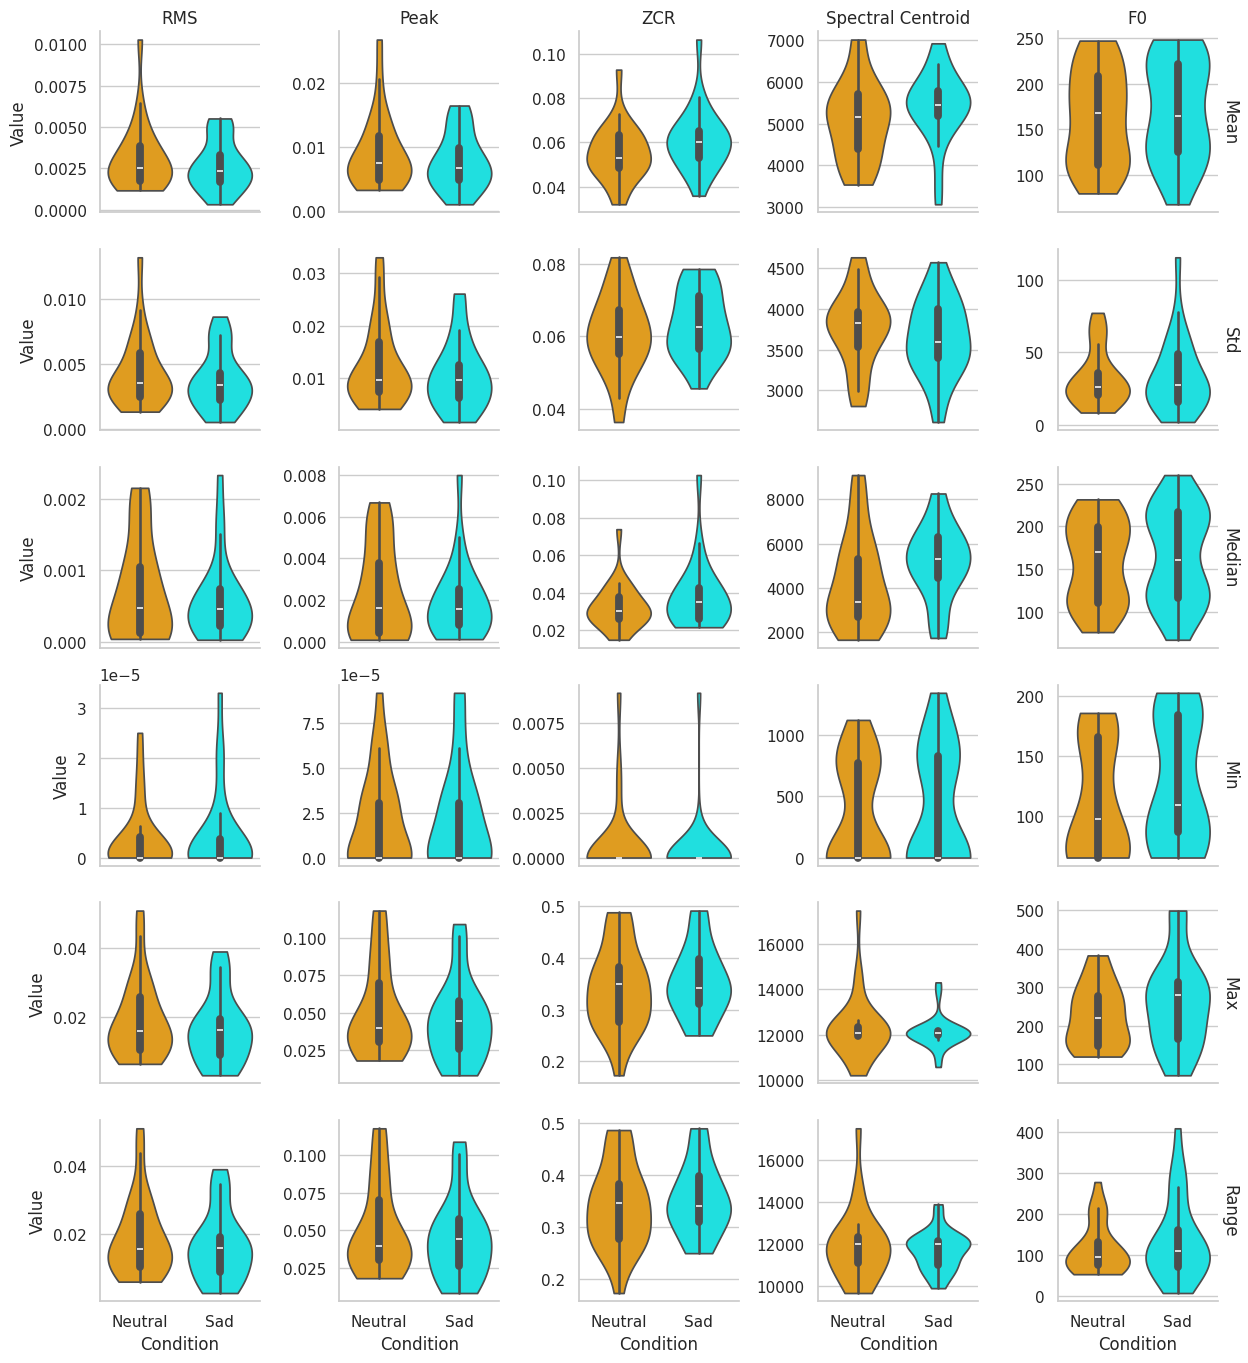

In [20]:
g = sns.catplot(
    data=df_plot,
    x="Condition",
    y="Value",
    col="Feature",
    row="Statistic",
    row_order=["Mean", "Std", "Median", "Min", "Max", "Range"],
    order=["Neutral", "Sad"],
    hue="Condition",
    palette={"Neutral": "orange", "Sad": "cyan"},
    kind="violin",
    inner="box",
    cut=0,
    sharey=False,
    height=2.3,
    aspect=1.1,
    legend=False,
    margin_titles=True
)

g.set_titles(
    col_template="{col_name}",
    row_template="{row_name}"
)

plt.show()

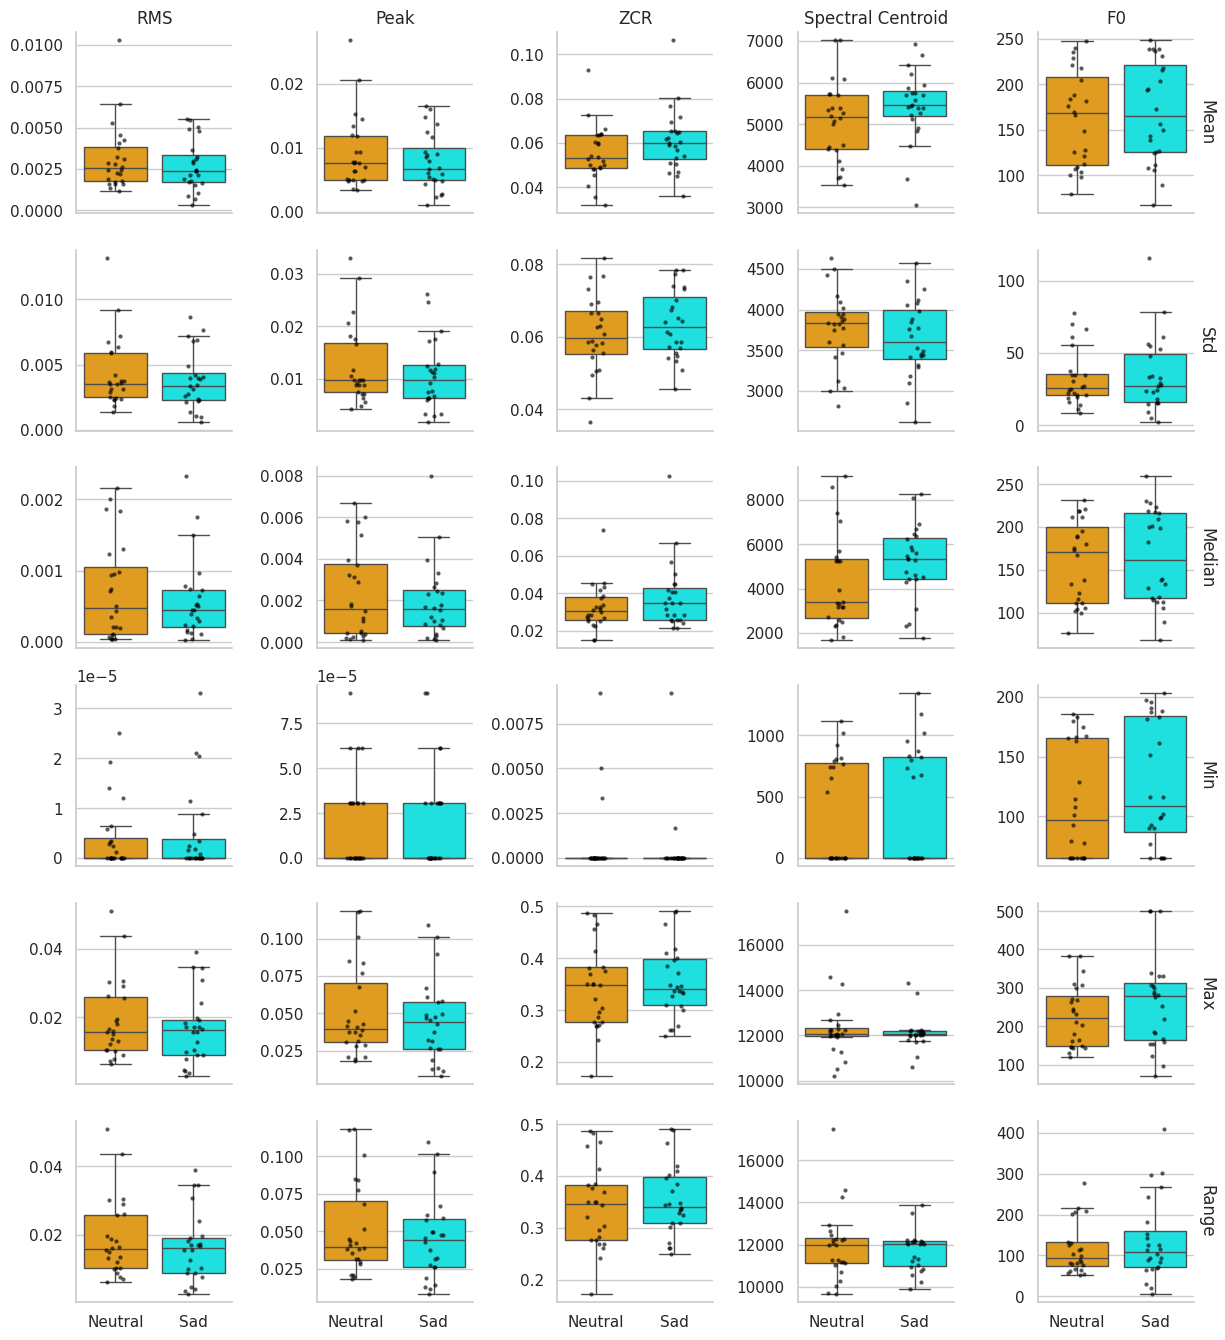

In [21]:
g = sns.catplot(
    data=df_plot,
    x="Condition",
    y="Value",
    col="Feature",
    row="Statistic",
    row_order=["Mean", "Std", "Median", "Min", "Max", "Range"],
    order=["Neutral", "Sad"],
    hue="Condition",
    palette={"Neutral": "orange", "Sad": "cyan"},
    kind="box",
    showfliers=False,
    sharey=False,
    height=2.3,
    aspect=1.1,
    legend=False,
    margin_titles=True
)

g.map_dataframe(
    sns.stripplot,
    x="Condition",
    y="Value",
    order=["Neutral", "Sad"],
    color="black",
    jitter=0.12,
    size=3,
    alpha=0.65
)

g.set_titles(
    col_template="{col_name}",
    row_template="{row_name}"
)
g.set_axis_labels("", "")
plt.show()

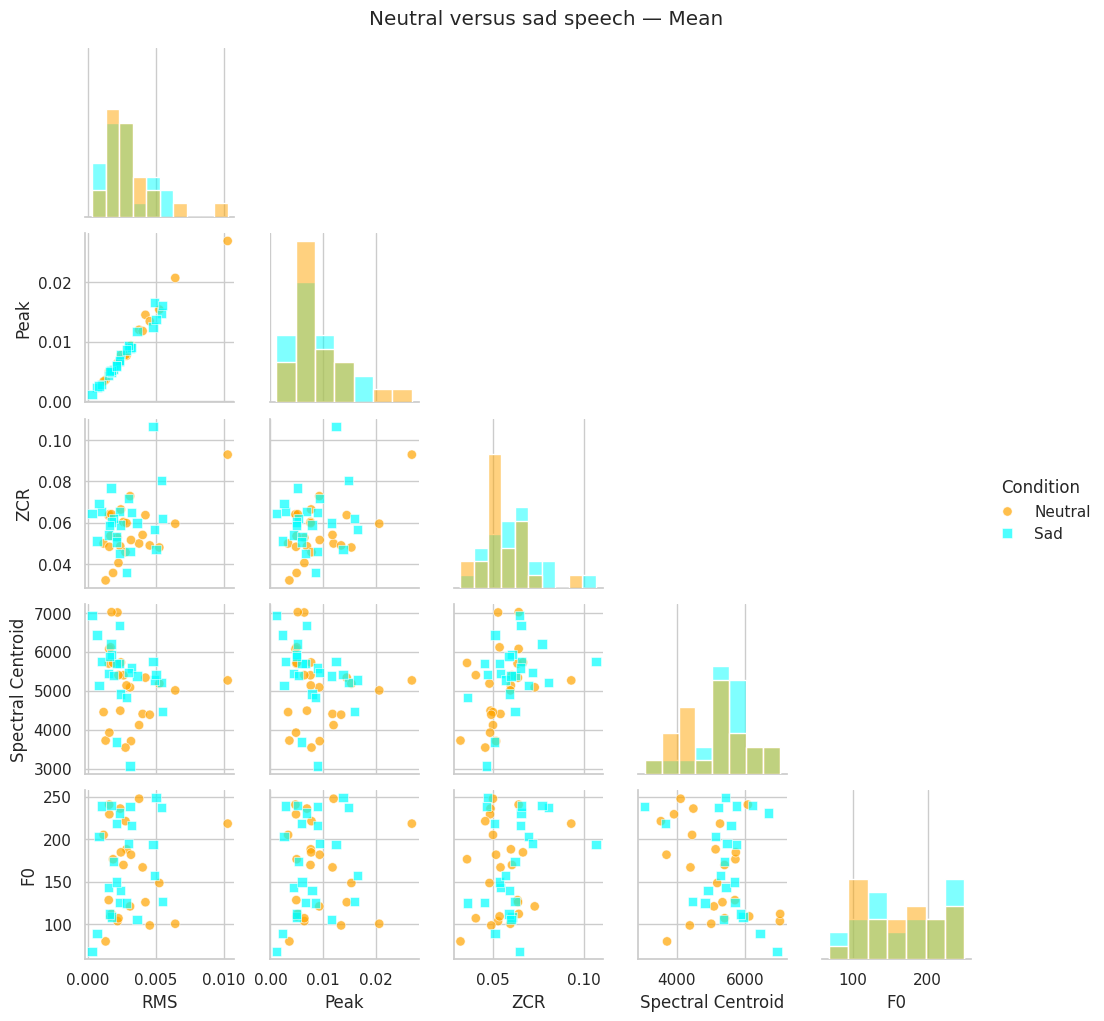

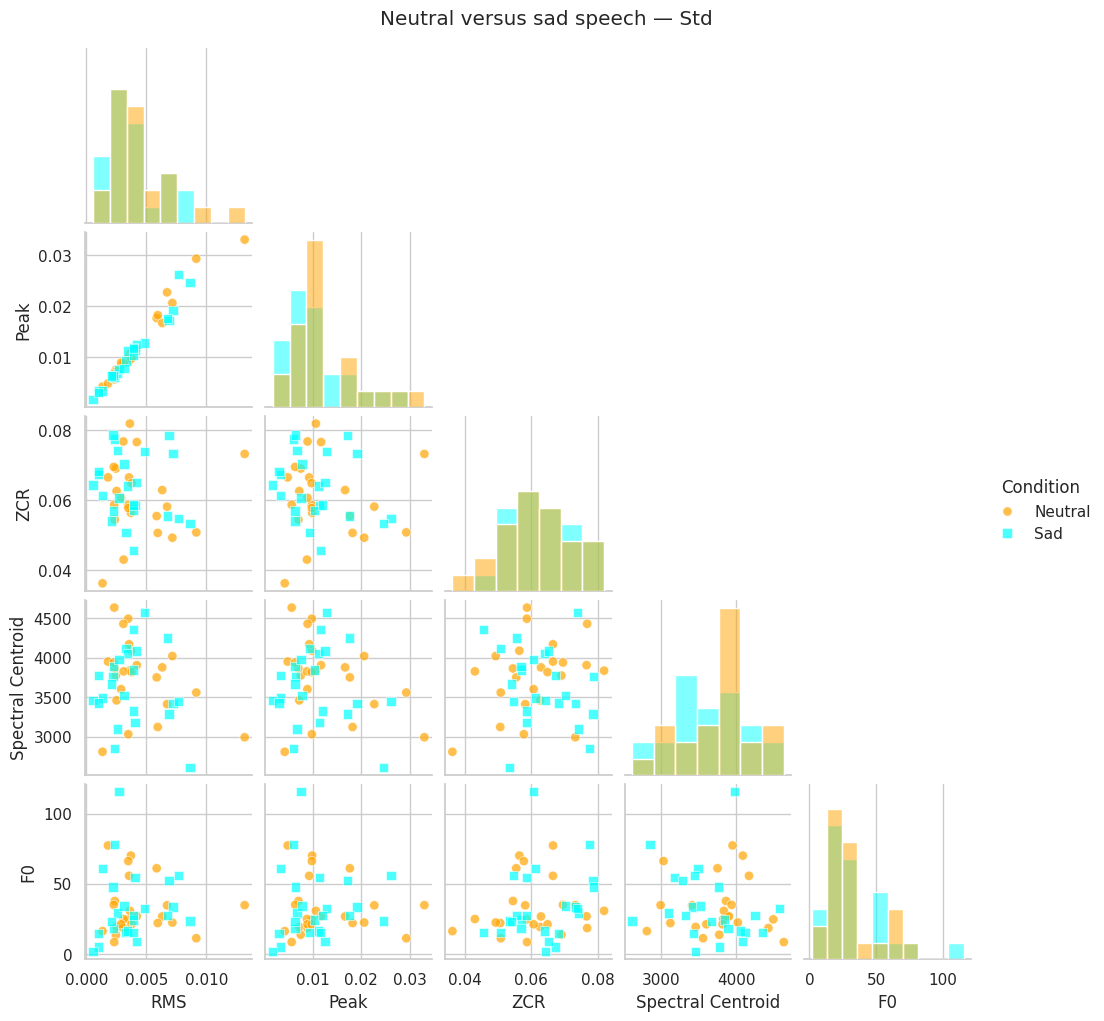

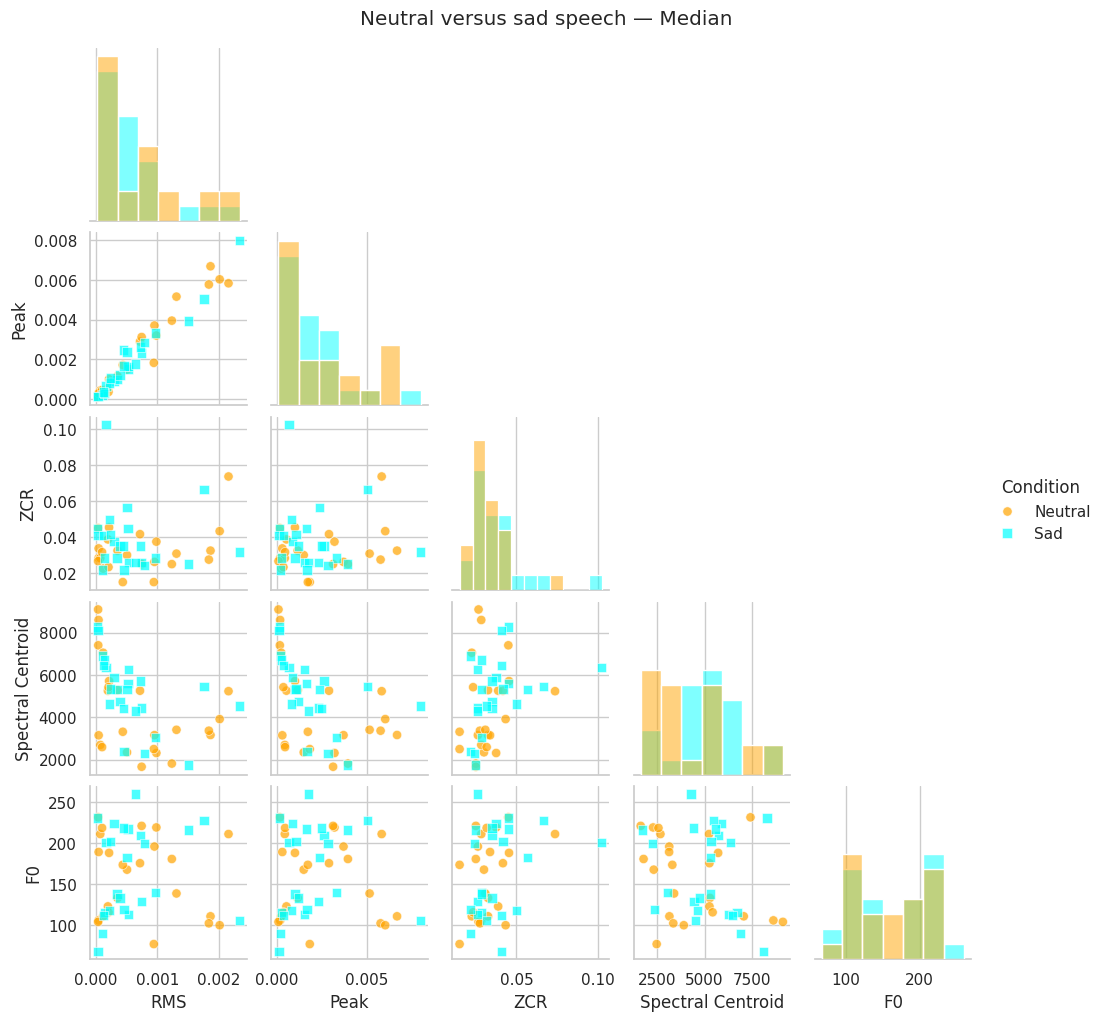

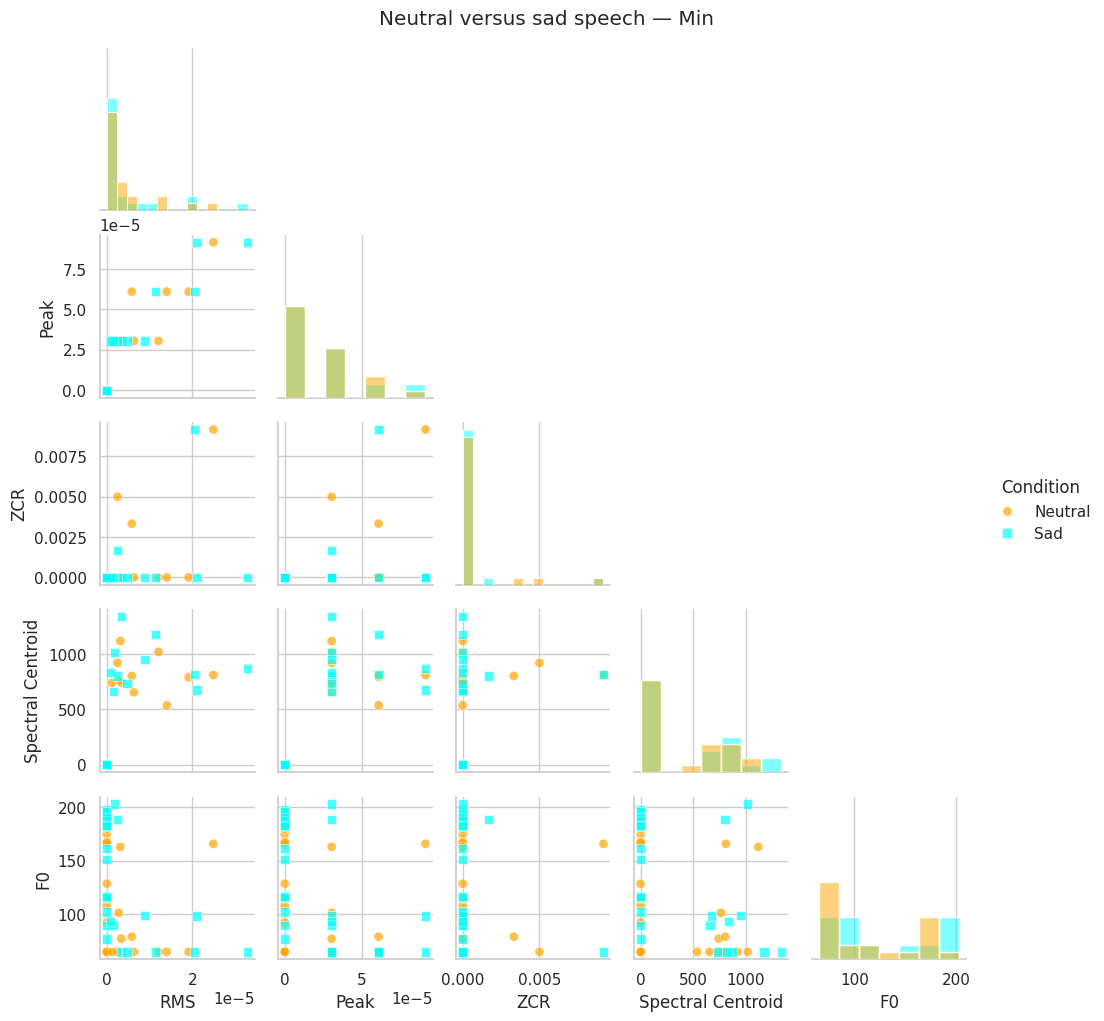

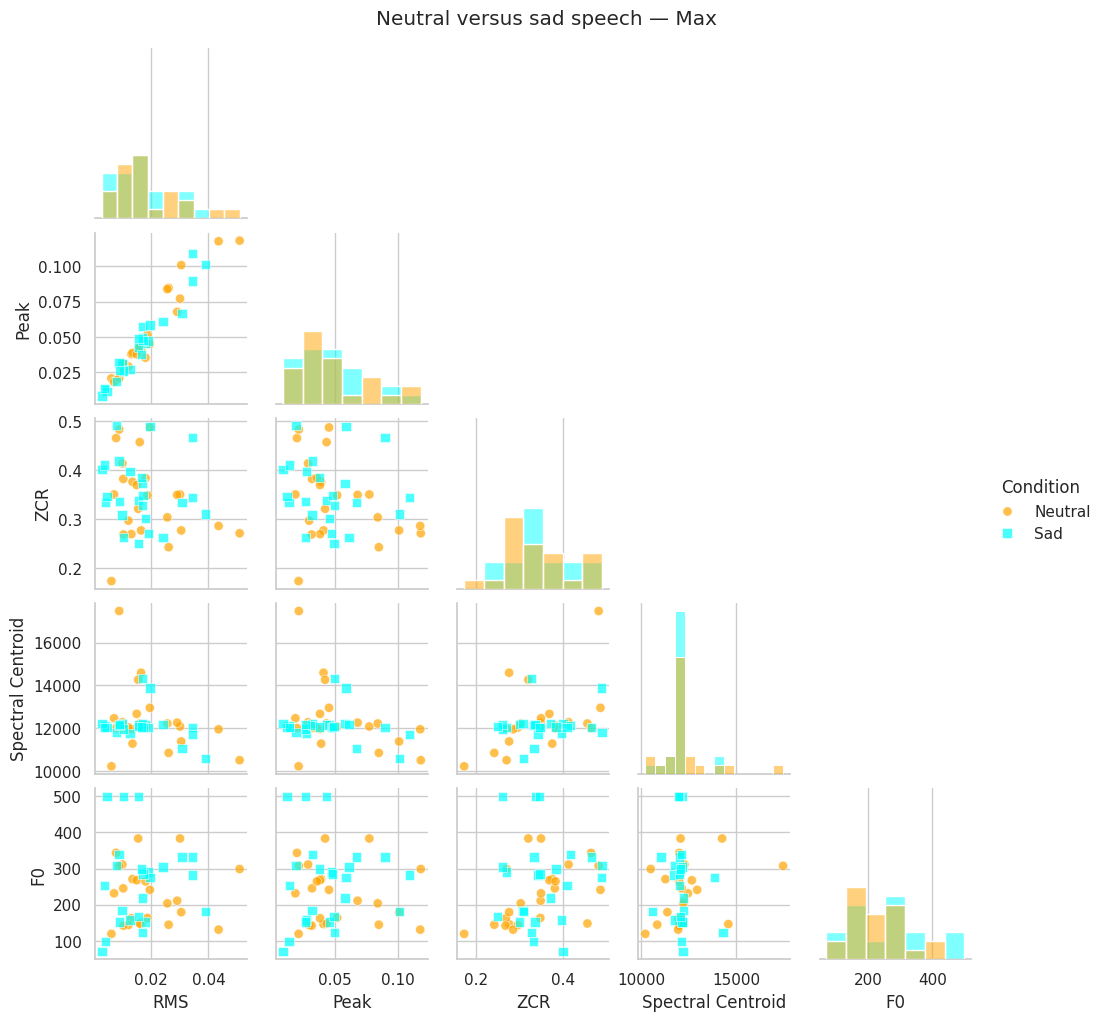

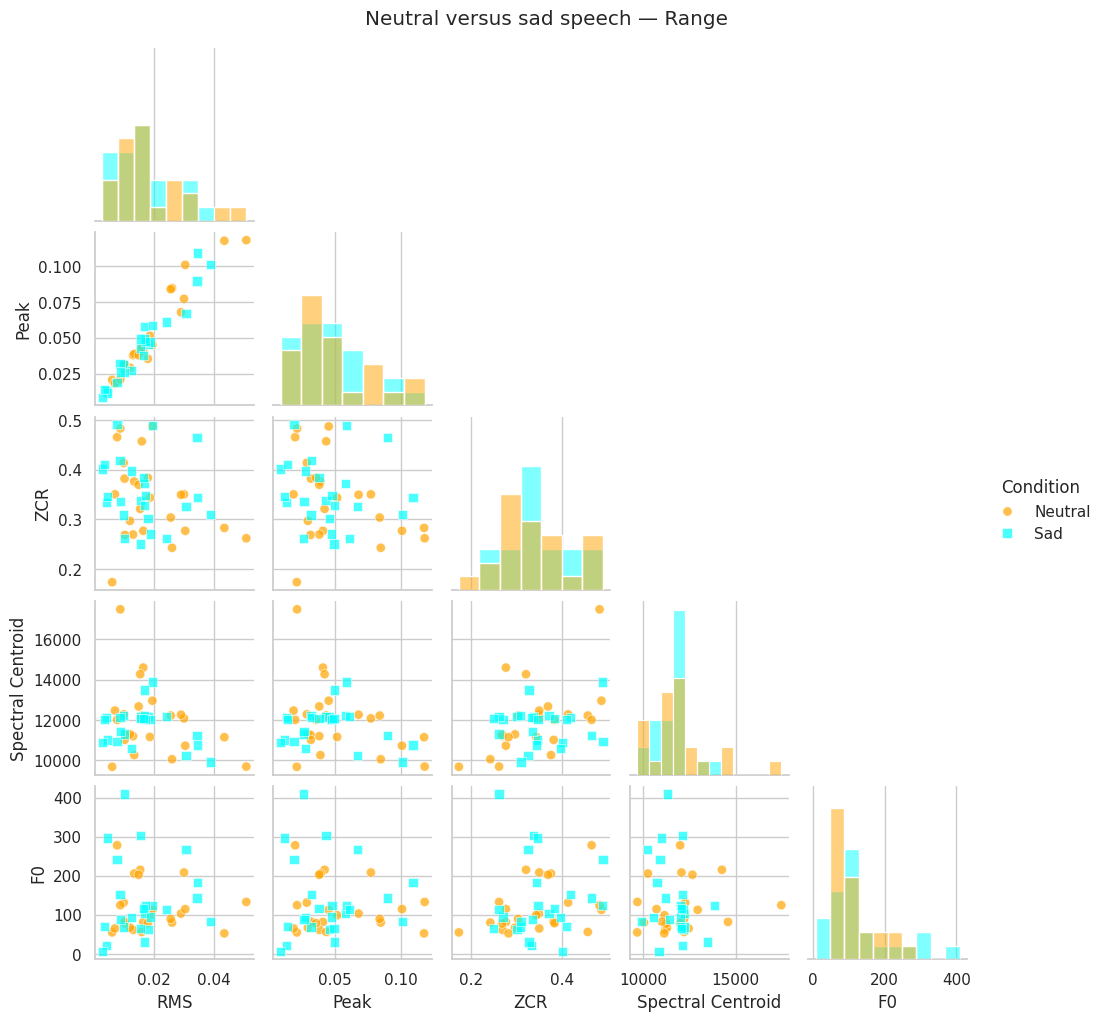

In [22]:
palette = {"Neutral": "orange", "Sad": "cyan"}

for statistic in ["Mean", "Std", "Median", "Min", "Max", "Range"]:

    neutral = df_normal.xs(
        statistic, level=1, axis=1
    ).copy()

    sad = df_sad.xs(
        statistic, level=1, axis=1
    ).copy()

    neutral["Condition"] = "Neutral"
    sad["Condition"] = "Sad"

    pairplot_data = pd.concat(
        [neutral, sad], ignore_index=True
    )

    g = sns.pairplot(
        data=pairplot_data,
        hue="Condition",
        hue_order=["Neutral", "Sad"],
        palette=palette,
        markers=["o", "s"],
        diag_kind="hist",
        corner=True,
        plot_kws={"alpha": 0.7, "s": 45},
        height=2
    )

    g.figure.suptitle(
        f"Neutral versus sad speech — {statistic}",
        y=1.02
    )

    plt.show()

RMS and peak amplitude show very similar patterns. The mean and standard deviation tend to be slightly lower in sad recordings, while neutral recordings include some larger amplitude values. This suggests a slight tendency toward lower amplitude and less amplitude variation in the selected sad recordings. However, the overlap is big, and the medians do not show an equal change. Therefore, the graphs do not support a consistent reduction in amplitude for every actor.

The min graph is not an strong indicator due to de lack of silence hnadling, minimal values are taken from the silence segments, making the max and range values rebundant. silence handling with activity segmentation in the windowing could have solved this issue.

Overall the median of the spectral centroid is the one that promises the most, at least for what is shown in the graphics, the center of the median distribution is approximately 3,400 Hz for neutral speech and 5,300 Hz for sad speech. The mean centroid also appears somewhat higher in sad recordings. But it is important to consider the impact of the silence in this.

The amount of data makes it hard to make assumptions, since it is not likely to be a representative of any kind, and barely show the kind of thistribution of each data. Few samples also mean that an outlayer has a greater impact in the data.

In [23]:
sad_aligned = df_sad.reindex(index=df_normal.index, columns=df_normal.columns)
df_differences = sad_aligned - df_normal  # Differences for paired actors

results = []
for feature, statistic in df_differences.columns:
    differences = df_differences[(feature, statistic)].dropna()
    p = np.nan
    if len(differences) >= 3 and differences.nunique() > 1:
        _, p = shapiro(differences)
    results.append({"Feature": feature, "Statistic": statistic,
                    "N pairs": len(differences), "Shapiro p-value": p})

df_normality = pd.DataFrame(results).set_index(["Feature", "Statistic"])
display(df_normality.round(4))  # p > 0.05 does not reject normality


N pairs  Shapiro p-value
Feature           Statistic                          
RMS               Mean            24           0.0678
                  Std             24           0.3970
                  Median          24           0.0063
                  Min             24           0.0001
                  Max             24           0.8625
                  Range           24           0.8632
Peak              Mean            24           0.1766
                  Std             24           0.2778
                  Median          24           0.0025
                  Min             24           0.0024
                  Max             24           0.8764
                  Range           24           0.8770
ZCR               Mean            24           0.9400
                  Std             24           0.5713
                  Median          24           0.1317
                  Min             24           0.0000
                  Max             24           0.6373
                  Range           24           0.6380
Spectral Centroid Mean            24           0.0852
                  Std             24           0.1324
                  Median          24           0.4779
                  Min             24           0.0035
                  Max             24           0.0001
                  Range           24           0.0043
F0                Mean            24           0.7431
                  Std             24           0.0014
                  Median          24           0.2777
                  Min             24           0.0019
                  Max             24           0.0011
                  Range           24           0.0051

In [24]:
from scipy.stats import wilcoxon

results = []
for feature, statistic in df_differences.columns:
    differences = df_differences[(feature, statistic)].dropna()
    if differences.empty:
        p = np.nan
    elif (differences == 0).all():
        p = 1.0
    else:
        _, p = wilcoxon(differences, alternative="two-sided")
    results.append({"Feature": feature, "Statistic": statistic, "Wilcoxon p-value": p})

df_wilcoxon = pd.DataFrame(results).set_index(["Feature", "Statistic"])
display(df_wilcoxon.round(4))


Wilcoxon p-value
Feature           Statistic                  
RMS               Mean                 0.1355
                  Std                  0.1434
                  Median               0.9888
                  Min                  0.9001
                  Max                  0.2076
                  Range                0.2076
Peak              Mean                 0.1074
                  Std                  0.1208
                  Median               1.0000
                  Min                  0.7963
                  Max                  0.2405
                  Range                0.2405
ZCR               Mean                 0.0457
                  Std                  0.2522
                  Median               0.1299
                  Min                  0.2850
                  Max                  0.4236
                  Range                0.4236
Spectral Centroid Mean                 0.1600
                  Std                  0.1434
                  Median               0.0425
                  Min                  0.6378
                  Max                  0.8334
                  Range                0.8996
F0                Mean                 0.2768
                  Std                  0.8553
                  Median               0.2768
                  Min                  0.0355
                  Max                  0.0646
                  Range                0.5646

In [32]:
from statsmodels.stats.multitest import multipletests

valid = df_wilcoxon["Wilcoxon p-value"].notna()

df_wilcoxon["Holm p-value"] = np.nan

df_wilcoxon.loc[valid, "Holm p-value"] = multipletests(df_wilcoxon.loc[valid, "Wilcoxon p-value"], alpha=0.05,method="holm")[1]#Holm correction controls multiple-testing familywise error (pairing is handled by Wilcoxon)

display(df_wilcoxon.round(4))

Wilcoxon p-value  Holm p-value
Feature           Statistic                                
RMS               Mean                 0.1355           1.0
                  Std                  0.1434           1.0
                  Median               0.9888           1.0
                  Min                  0.9001           1.0
                  Max                  0.2076           1.0
                  Range                0.2076           1.0
Peak              Mean                 0.1074           1.0
                  Std                  0.1208           1.0
                  Median               1.0000           1.0
                  Min                  0.7963           1.0
                  Max                  0.2405           1.0
                  Range                0.2405           1.0
ZCR               Mean                 0.0457           1.0
                  Std                  0.2522           1.0
                  Median               0.1299           1.0
                  Min                  0.2850           1.0
                  Max                  0.4236           1.0
                  Range                0.4236           1.0
Spectral Centroid Mean                 0.1600           1.0
                  Std                  0.1434           1.0
                  Median               0.0425           1.0
                  Min                  0.6378           1.0
                  Max                  0.8334           1.0
                  Range                0.8996           1.0
F0                Mean                 0.2768           1.0
                  Std                  0.8553           1.0
                  Median               0.2768           1.0
                  Min                  0.0355           1.0
                  Max                  0.0646           1.0
                  Range                0.5646           1.0

The separability analysis suggests that the extracted acoustic measurements have limited individual ability to distinguish neutral from sad speech. The analysis includes 48 recordings from 24 actors, with one recording per condition for each actor. Most feature distributions have big overlaps, meaning a bad separability, thus making .

Median spectral centroid and mean ZCR show promising patterns and the paired test. Their unadjusted Wilcoxon p-values are 0.0425 and 0.0457, respectively. Minimum F0 also produces an unadjusted p-value below 0.05 (0.0355), but this measurement is sensitive to isolated pitch-estimation errors. However, none of the 30 comparisons remains statistically significant after Holm adjustment.

These statistical results assess paired differences, rather than directly measuring classification performance. A significant difference can coexist with considerable overlap, while nonsignificant individual features may still contribute information when combined. Therefore, the current results do not establish how accurately a multivariate model could classify the recordings.

The observed overlap may reflect both variability between actors and limitations of the processing, including silence-sensitive features, recording truncation, and the loss of temporal information when window measurements are reduced to summary statistics. With only 24 actor pairs, the evidence is also limited. The conclusions apply to these selected acted neutral and sad recordings and do not establish whether the features can distinguish clinical depression.

#5.	Data separability

In [138]:
from sklearn.base import clone
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix)


In [157]:
selected_columns = [("Spectral Centroid", "Median"), ("F0", "Min"), ("ZCR", "Mean")] #only the 3 best

#selected_columns = [column for column in df_normal.columns if column[1] not in ["Min", "Range"]]

assert df_normal.index.is_unique and df_sad.index.is_unique
assert set(df_normal.index) == set(df_sad.index)

sad_aligned = df_sad.reindex(index=df_normal.index)

X = pd.concat([df_normal[selected_columns], sad_aligned[selected_columns]], ignore_index=True)

y = np.array([0] * len(df_normal) + [1] * len(sad_aligned))

groups = np.tile(df_normal.index.to_numpy(), 2)

In [158]:
models = {
    "Logistic regression": make_pipeline(
        SimpleImputer(strategy="median"),
        LogisticRegression(
            solver="liblinear",
            max_iter=10000,
            random_state=42
        )
    ),

    "Standardized logistic regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(
            solver="liblinear",
            max_iter=10000,
            random_state=42
        )
    ),

    "Decision tree": make_pipeline(
        SimpleImputer(strategy="median"),
        DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=4,
            random_state=42
        )
    )
}

cv = LeaveOneGroupOut()

results = []
predictions = {}
probabilities = {}

for name, model in models.items():
    predicted_labels = np.zeros(len(y), dtype=int)
    predicted_probabilities = np.zeros(len(y))

    for train_index, test_index in cv.split(X, y, groups):
        fitted_model = clone(model)

        fitted_model.fit(X.iloc[train_index], y[train_index])

        predicted_labels[test_index] = fitted_model.predict(X.iloc[test_index])

        predicted_probabilities[test_index] = (fitted_model.predict_proba(X.iloc[test_index])[:, 1])

    predictions[name] = predicted_labels
    probabilities[name] = predicted_probabilities

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y, predicted_labels),
        "Precision": precision_score(
            y, predicted_labels, zero_division=0
        ),
        "Recall": recall_score(
            y, predicted_labels, zero_division=0
        ),
        "F1-score": f1_score(
            y, predicted_labels, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y, predicted_probabilities
        )
    })

df_performance = pd.DataFrame(results).set_index("Model")

display(df_performance.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic regression,0.6042,0.5862,0.7083,0.6415,0.6476
Standardized logistic regression,0.6042,0.6316,0.5000,0.5581,0.6753
Decision tree,0.6042,0.6316,0.5000,0.5581,0.6285


all features except min and range

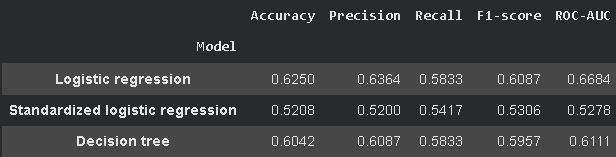

only spectral median, F0 min and ZCR mean


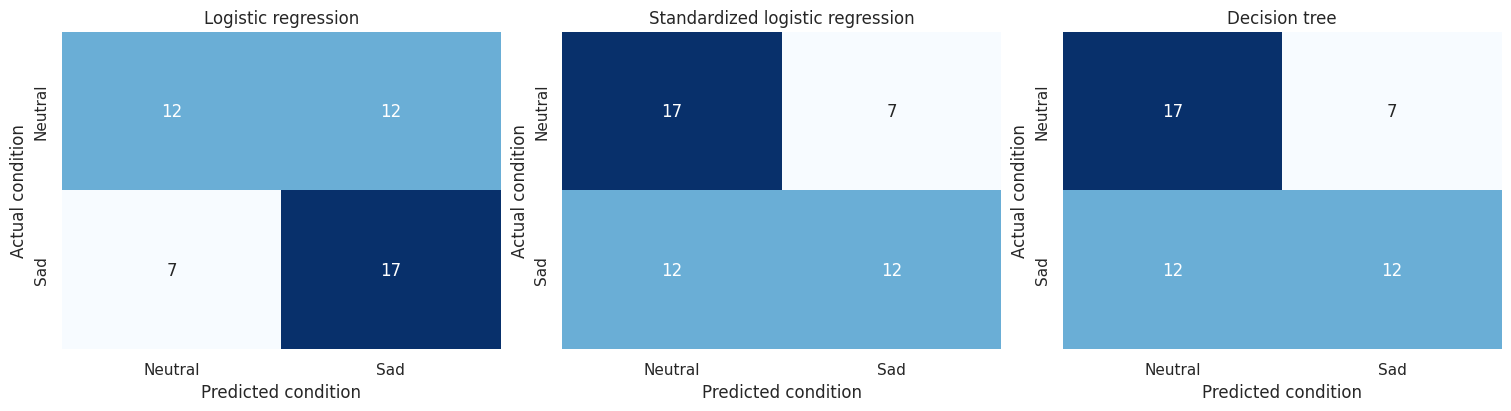

In [159]:
fig, axes = plt.subplots(
    1, len(models),
    figsize=(15, 4),
    constrained_layout=True
)

for ax, name in zip(axes, models):
    matrix = confusion_matrix(
        y, predictions[name], labels=[0, 1]
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Neutral", "Sad"],
        yticklabels=["Neutral", "Sad"],
        ax=ax
    )

    ax.set(
        title=name,
        xlabel="Predicted condition",
        ylabel="Actual condition"
    )
print('only spectral median, F0 min and ZCR mean')
plt.show()

all features except min and range

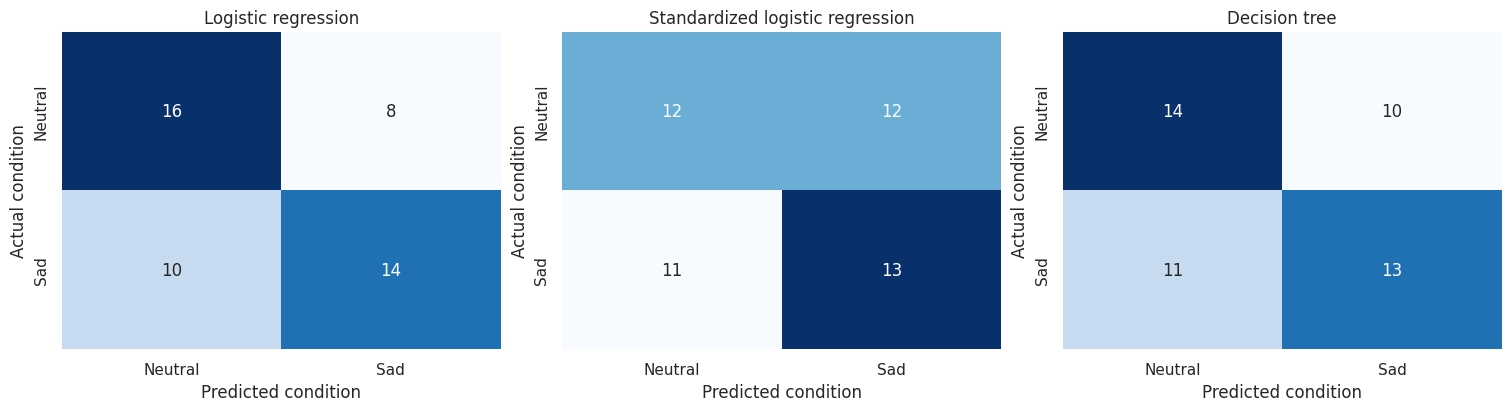

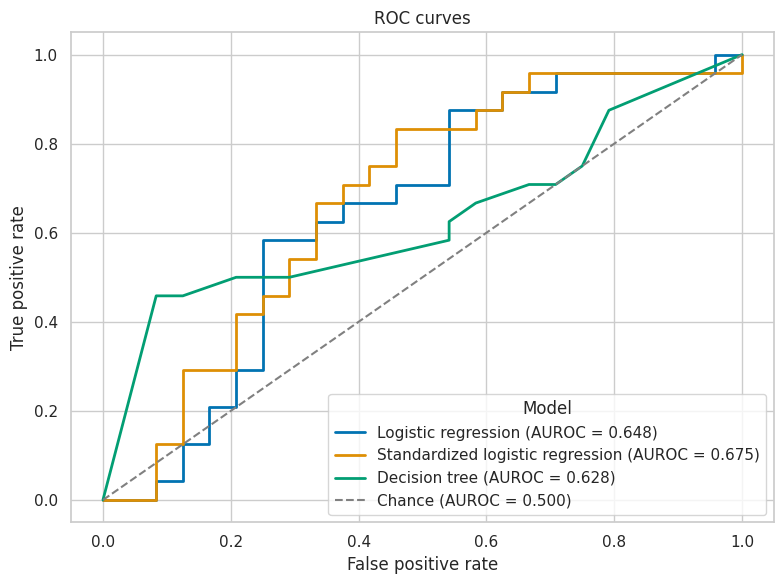

In [124]:
from sklearn.metrics import roc_curve, roc_auc_score

roc_data = []

for name, model_probabilities in probabilities.items():
    fpr, tpr, _ = roc_curve(y, model_probabilities)
    auc = roc_auc_score(y, model_probabilities)

    roc_data.append(pd.DataFrame({
        "FPR": fpr,
        "TPR": tpr,
        "Model": f"{name} (AUROC = {auc:.3f})"
    }))

df_roc = pd.concat(roc_data, ignore_index=True)

plt.figure(figsize=(8, 6))

sns.lineplot(
    data=df_roc,
    x="FPR",
    y="TPR",
    hue="Model",
    palette="colorblind",
    linewidth=2,
    estimator=None,
    sort=False
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Chance (AUROC = 0.500)"
)

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves")
plt.legend(title="Model", loc="lower right")
plt.tight_layout()
plt.show()

all features but min and range

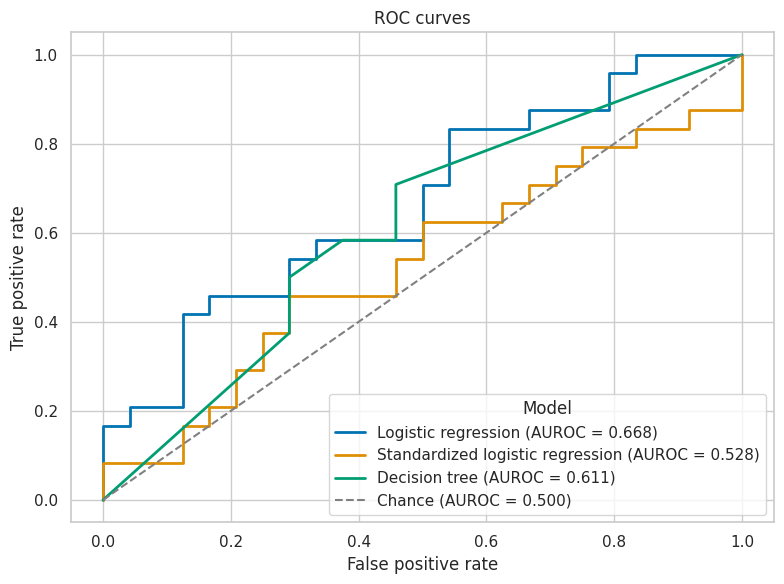

As expected, the clasification capabilities of the model are poor, with an AUCROC ranging from 0.611 to 0.675 the model does not classify as usefull even, yet, taking in consideration the quality and amount of the data, is personally surprising it has any way of predicting, the stadarized logistic regresion, had a somewhat noticable recall at the cost of a worst accuracy meaning it was labeling a lot of the subjects as sad, but overall the model where not remarkable.

This results doesn't mean is not posible to calssify sad acting from non sad acting with vioce data, nor that the problem is entirely the data processing, the features used for the detection where based in actual depression detection, not mood nor mood acting, in order to get good results there shuld be a change in the focus, not only in the processing but in the approach done.

there was an small improvement in the model that uses the only significant unadjusted p-value features, this could mean that the features are selected are more significant in terms of information compared to the others